In [31]:
import matplotlib.pyplot as plt
import numpy as np
import os
import h5py as h5
from scipy.sparse import csc_array
from matplotlib.ticker import FuncFormatter, FixedLocator

In [32]:
site_dict = {"Duskey Sound": "1098000_4902000",
             "Milford Sound": "1197000_5037000",
             "South Fjordland": "1134000_4866000"}
sitename = "South Fjordland"

interval='100'

h5_File = "./results/puysegur/weighted_mean_PPE_dict_3_branch.h5"

wh5 = h5.File(h5_File, 'r')

In [33]:
wh5[site_dict[sitename]][interval].keys()

<KeysViewHDF5 ['branch_exceedance_probs_down', 'branch_exceedance_probs_up', 'down_weighted_percentile_error', 'down_weighted_percentile_error_indices', 'down_weighted_percentile_error_indptr', 'meta', 'up_weighted_percentile_error', 'up_weighted_percentile_error_indices', 'up_weighted_percentile_error_indptr', 'weighted_exceedance_probs_down', 'weighted_exceedance_probs_up']>

In [34]:
wh5[site_dict[sitename]][interval]['meta'][:]

array([0.e+00, 1.e+01, 1.e-02, 1.e+05])

In [35]:
thresholds = np.arange(wh5[site_dict[sitename]][interval]['meta'][0], wh5[site_dict[sitename]][interval]['meta'][1] + wh5[site_dict[sitename]][interval]['meta'][2], wh5[site_dict[sitename]][interval]['meta'][2])

In [36]:
weights = wh5['branch_weights'][:]
weight_order = np.argsort(weights)
c_weight = weights / max(weights)
colours = plt.get_cmap('plasma')(c_weight)

In [37]:
wh5[site_dict[sitename]][interval].keys()

<KeysViewHDF5 ['branch_exceedance_probs_down', 'branch_exceedance_probs_up', 'down_weighted_percentile_error', 'down_weighted_percentile_error_indices', 'down_weighted_percentile_error_indptr', 'meta', 'up_weighted_percentile_error', 'up_weighted_percentile_error_indices', 'up_weighted_percentile_error_indptr', 'weighted_exceedance_probs_down', 'weighted_exceedance_probs_up']>

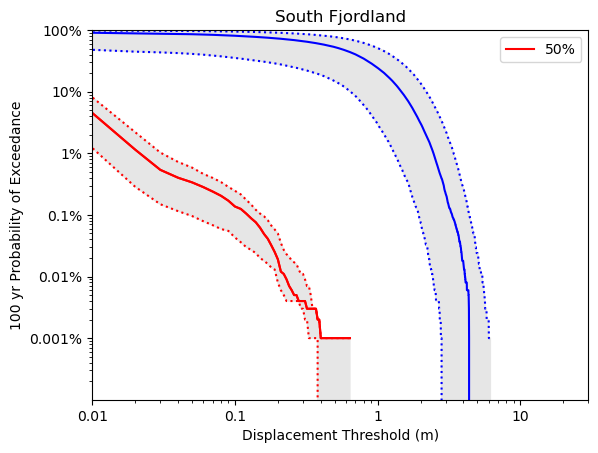

In [38]:
exceed_type, ecolor = 'up', 'red'
n_thresh = wh5[site_dict[sitename]][interval][f'branch_exceedance_probs_{exceed_type}'].shape[0]
weighted_percentile_error = csc_array((wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error"], wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error_indices"], wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error_indptr"])).toarray()
plt.fill_between(thresholds[:n_thresh], weighted_percentile_error[5, :], weighted_percentile_error[1, :], color='0.9')
plt.plot(thresholds[:n_thresh], weighted_percentile_error[3, :], color=ecolor, linestyle="-", label="50%")
# plt.plot(thresholds[:n_thresh], weighted_percentile_error[4, :], color=ecolor, linestyle=":", label="1 Sigma")
# plt.plot(thresholds[:n_thresh], weighted_percentile_error[5, :], color=ecolor, linestyle="--", label="2 Sigma")
# plt.plot(thresholds[:n_thresh], weighted_percentile_error[1, :], color=ecolor, linestyle="--")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[4, :], color=ecolor, linestyle=":")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[2, :], color=ecolor, linestyle=":")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[3, :], color=ecolor, linestyle="-")
exceed_type, ecolor  ='down', 'blue'
n_thresh = wh5[site_dict[sitename]][interval][f'branch_exceedance_probs_{exceed_type}'].shape[0]
weighted_percentile_error = csc_array((wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error"], wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error_indices"], wh5[site_dict[sitename]][interval][f"{exceed_type}_weighted_percentile_error_indptr"])).toarray()
plt.fill_between(thresholds[:n_thresh], weighted_percentile_error[5, :], weighted_percentile_error[1, :], color='0.9')
# plt.plot(thresholds[:n_thresh], weighted_percentile_error[5, :], color=ecolor, linestyle="--")
# plt.plot(thresholds[:n_thresh], weighted_percentile_error[1, :], color=ecolor, linestyle="--")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[4, :], color=ecolor, linestyle=":")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[2, :], color=ecolor, linestyle=":")
plt.plot(thresholds[:n_thresh], weighted_percentile_error[3, :], color=ecolor, linestyle="-")

plt.yscale('log')
plt.xscale('log')
plt.legend()
plt.title(sitename)

xmin, xmax = 0.01, 30
ymin, ymax = 0.000001, 1
plt.ylim([ymin, ymax])
plt.yticks([0.00001, 0.0001, 0.001, 0.01, 0.1, 1])
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y*100:g}%")
)
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:g}")
)
plt.xlim([xmin, xmax])
plt.ylabel('100 yr Probability of Exceedance')
plt.xlabel('Displacement Threshold (m)')

plt.savefig(f"./{sitename}_py.pdf")

In [39]:
wh5.close()